# Journal Study: What are the Top Journals / Conferences in Data Analysis?

This is the main driving question that this notebook seeks to answer. Throughout this notebook, we will anchor our analysis on top research institutions / universities to gain a clearer idea of what top researchers in the field implicitly "favor" or "deem" as prestigious journals. In answering the driving question, we will also answer the following sub-questions:

- Section 6.1 - Which research universities publish the most in data analysis?
- Section 6.2 - Which research universities have the most faculty that published in Nature, Science or PNAS?
- Section 6.3 - Which journals / conferences are implicitly "favored" by each top university?
- Section 6.4 - Which journals / conferences do the data science faculty of top universities publish to over the years (popularity)?
- Section 6.5 - For each scholarly metric, what are their top journals / conferences?
- Section 6.6 - How can we rank the journals / conferences based on prestige (e.g. Premium, Leading, Reputable)?
- Section 6.7 - What are the top themes or keywords present in the accepted works of prestigious journals?

This notebook primarily collects its research data from [OpenAlex](https://openalex.org/); it provides a handy [API](https://developers.openalex.org/) that is available at no cost (with restrictions). Creating an OpenAlex account is recommended to run this notebook, since this will increase the number of free API requests per day.

This notebook extracts the following data in this order: (1) topics in the field of data analysis, (2) top research institutions, (3) related journals / conferences, (4) scholarly metrics. Afterwards, analysis of the data and findings are presented in Section 5.

### Dependencies

In [ ]:
%pip install python-dotenv stop-words keybert bertopic -q

In [1]:
import os
import requests
import json
from collections import defaultdict, Counter
import matplotlib.pyplot as plt
import copy
import pandas as pd
import time
import ijson

from dotenv import load_dotenv
from stop_words import get_stop_words
from datetime import datetime
from pathlib import Path

from sklearn.feature_extraction.text import CountVectorizer
from keybert import KeyBERT
from bertopic import BERTopic
from bertopic.representation import KeyBERTInspired
from sentence_transformers import SentenceTransformer

from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
import matplotlib.colors as mcolors

### Setup

In [2]:
load_dotenv()

api_key = os.getenv("OPENALEX_API_KEY")

### Helper Functions

In [2]:
# OpenAlex API endpoint
BASE = "https://api.openalex.org"
def api(endpoint, params):
    return requests.get(f"{BASE}/{endpoint}", params=params).json()

# Check if a word contains any of the listwords
def word_contains_any_listwords(word, list):
    for listword in list:
        if listword.lower() in word.lower():
            return True
    return False


# Reconstruct a work's abstract from index
def reconstruct_abstract(abstract_inverted_index, excluded_words):
    try:
        if not abstract_inverted_index:
            return ""

        max_pos = max(pos for positions in abstract_inverted_index.values() for pos in positions)
        words = [None] * (max_pos + 1)

        for word, positions in abstract_inverted_index.items():
            if not word_contains_any_listwords(word, excluded_words):
                for pos in positions:
                    words[pos] = word
            else:
               for pos in positions:
                    words[pos] = "" 

        return " ".join(words)
    except Exception:
        return None

# Truncate text if it is too long
def truncate_text(text, max_length=70):
    if len(text) > max_length:
        return text[:max_length] + "..."
    return text

## Section 1: Processing Institutions

Our list will contain 10 institutions / universities only. For our selection of the top universities, we will base it on the [QS University Ranking by Data Science and AI](https://www.topuniversities.com/university-subject-rankings/data-science-artificial-intelligence). From this list, we select **at least one** top university in the following countries: US, Singapore, China, and Japan.

US:
- Massachusetts Institute of Technology (MIT)
- Stanford University
- Carnegie Mellon University (CMU)
- University of California, Berkeley (UCB)
- Harvard University

Singapore:
- National University of Singapore (NUS)
- Nanyang Technological University (NTU)

China:
- Tsinghua University
- Peking University

Japan:
- The University of Tokyo

In [3]:
# Top universities in Data Science and AI (based on QS Universities Rankings)
# https://www.topuniversities.com/university-subject-rankings/data-science-artificial-intelligence

TOP_UNIS = [
    "mit",          # Massachusetts Institute of Technology
    "stanford",     # Stanford University
    "cmu",          # Carnegie Mellon University
    "ucb",          # University of California, Berkeley
    "harvard",      # Harvard University
    "nus",          # National University of Singapore
    "ntu",          # Nanyang Technological University
    "tsinghua",     # Tsinghua University
    "peking",       # Peking University
    "utokyo",       # The University of Tokyo
]

In [7]:
top_unis_id = []

# Get institution ID from university name
for uni in TOP_UNIS:
    print(uni)

    response = api("institutions", {
        "search": uni,
        "api_key": api_key
    })

    if "error" in response:
        print(response["error"])
        print(response["message"])
        break

    uni_url = response["results"][0]["id"]
    uni_id = uni_url.rpartition('/')[-1]

    top_unis_id.append([uni, uni_id])

mit
stanford
cmu
ucb
harvard
nus
ntu
tsinghua
peking
utokyo


In [ ]:
print(top_unis_id)

[['mit', 'I63966007'], ['stanford', 'I97018004'], ['cmu', 'I74973139'], ['ucb', 'I95457486'], ['harvard', 'I136199984'], ['nus', 'I165932596'], ['ntu', 'I172675005'], ['tsinghua', 'I99065089'], ['peking', 'I20231570'], ['utokyo', 'I74801974']]


In [ ]:
# OPTIONAL: Save top universities and their IDs as JSON
with open("top_unis_id.json", "w", encoding="utf-8") as f:
    json.dump(top_unis_id, f, indent=4)

##  Section 2: Extracting Authors + Works

### 2.1 Collating Names of Faculty

For each university, we collate the names of the current faculty pool under either the **computing** or **data science** departments. This step was done manually as each university organizes their schools and faculty lists differently. The faculty names were inputted in `.txt` files corresponding to their university, and saved in the `faculty` folder.

### 2.2 Assigning Author IDs

NOTE: Please skip to Section 2.3 if you already have the `.json` files containing the faculty-to-ID mappings, located in the `faculty_ids` folder.

From the `.txt` files, we automatically extract and assign each faculty with their OpenAlex Author ID. We begin by reading the `.txt` files line-by-line and storing the faculty names in a list we call `authors`. Then, we will extract their OpenAlex Author IDs programatically. Also, for clarity, "faculty" and "author" refer to the same thing throughout this notebook — though "author" is the official term on OpenAlex.

In [ ]:
output_dir = Path("./faculty_ids")
output_dir.mkdir(exist_ok=True)

for uni_name, uni_id in top_unis_id:
    authors = []
    author_ids = {}

    with open(f"./faculty/faculty_{uni_name}.txt", "r") as file:
        for line in file:
            authors.append(line.strip())

    for author in authors:
        response = api("authors", {
            "filter": f"last_known_institutions.id:{uni_id}",
            "search": author,
            "select": "id",
            "api_key": api_key,
        })

        if "error" in response:
            print(response["error"])
            print(response["message"])
            break

        results = response["results"]
        author_ids[author] = [author_url["id"].rpartition('/')[-1] for author_url in results]

    # Save all authors as JSON
    with open(output_dir / f"faculty_{uni_name}_ids.json", "w", encoding="utf-8") as file:
        json.dump(author_ids, file, indent=4)

By assigning OpenAlex Author IDs to each faculty, we can easily extract their published works later on.

In [ ]:
authors = []
with open(f"./faculty/faculty_utokyo.txt", "r") as file:
    for line in file:
        authors.append(line.strip())

author_ids = {}
with open("./faculty_ids/faculty_utokyo_ids.json", "r") as file:
    author_ids = json.load(file)

Essentially, we convert a `faculty.txt` file like this...

In [ ]:
print(authors)

['Yoshia ABE', 'Yuina ABE', 'Yusuke AIKAWA', 'Dai AKITA', 'Kaoru AMANO', 'Kazuma AOYAMA', 'Takuto ASAKURA', 'Masaki ASANO', 'Max AUSTIN', 'JEONGHUN BAEK', 'HAOZHI CAO', 'Sankardeep CHAKRABORTY', 'Shigeru CHIBA', 'FENG DAI', 'Tatsuya DAIKOKU', 'Hiroshi DOHI', 'Naohiro EDA', 'Hiroshi ESAKI', 'Takanori FUKAO', 'XINYUE GUI', 'Masami HAGIYA', 'Shun HASEGAWA', 'Satoshi HAYAKAWA', 'Koyo HAYASHI', 'Ryohei HISANO', 'Ryoichi HORISAKI', 'Yamasaki Hayata', 'Hitoshi IBA', 'Ayumi IGARASHI', 'Takeo IGARASHI', 'Katsuma INOUE', 'Hidetsugu IRIE', 'Hideaki ISHII', 'Kaito ITO', 'Masaki ITO', 'Shinji ITO', 'Satoru IWATA', 'EHSAN JAVANMARDI', 'XIANG JI', 'BYEONGWOOK JO', 'Junichiro KADOMOTO', 'Hoshinori KANAZAWA', 'Yoshihiro KANNO', 'Yasuhiro KATO', 'Kento KAWAHARAZUKA', 'Kenichi KAWARABAYASHI', 'Yoshiaki KAWASE', 'Kenji KAWASHIMA', 'Naoki KOBAYASHI', 'Ryosuke KOBAYASHI', 'Kunio KOJIMA', 'Fumiyasu KOMAKI', 'Ryoma KONDO', 'Ryota KONDO', 'Tomoyuki KUBOTA', 'Yasuo KUNIYOSHI', 'Hideaki KUZUOKA', 'LEI MA', 'Ryog

And export it to a `faculty_ids.json` file like this...

In [ ]:
print(author_ids)

{'Yoshia ABE': ['A5111142506'], 'Yuina ABE': [], 'Yusuke AIKAWA': ['A5054646111'], 'Dai AKITA': ['A5092089100', 'A5033206436', 'A5132818998'], 'Kaoru AMANO': ['A5064555684', 'A5064760425', 'A5137141491'], 'Kazuma AOYAMA': ['A5054298627', 'A5008649641', 'A5132820831'], 'Takuto ASAKURA': ['A5035501777'], 'Masaki ASANO': [], 'Max AUSTIN': ['A5016760292', 'A5123171358', 'A5136185615'], 'JEONGHUN BAEK': ['A5065773265'], 'HAOZHI CAO': [], 'Sankardeep CHAKRABORTY': ['A5087759069'], 'Shigeru CHIBA': ['A5026542200', 'A5103031063'], 'FENG DAI': ['A5111579618', 'A5077717482', 'A5036512030'], 'Tatsuya DAIKOKU': ['A5089417940', 'A5103269604', 'A5133265462', 'A5128346878'], 'Hiroshi DOHI': [], 'Naohiro EDA': [], 'Hiroshi ESAKI': ['A5052106822'], 'Takanori FUKAO': ['A5112318413'], 'XINYUE GUI': ['A5062839476'], 'Masami HAGIYA': ['A5110590293'], 'Shun HASEGAWA': ['A5078551479'], 'Satoshi HAYAKAWA': ['A5135744180'], 'Koyo HAYASHI': ['A5044015212'], 'Ryohei HISANO': ['A5057799988'], 'Ryoichi HORISAKI': 

Note that some authors have more than one OpenAlex Author ID, but that is okay. The reason is based on how OpenAlex assigns Author IDs — when a faculty moves to another university, a new Author ID is created since the works that they publish henceforth are now belonging to that university. Consequently, some faculty can have multiple Author IDs but we keep in mind that they are still same person, so we consider all their Author IDs.

### 2.3 Extracting Works by Institution and Author IDs as JSON

Let's fetch all the works of each faculty. We want to exclude medical works, so we will create a list of medical-related keywords to filter each work by.

In [ ]:
MEDICAL_KEYWORDS = [
    "medic",
    "health",
    "disease",
    "protein",
    "drug",
    " genes ",
    " gene ",
    "genet",
    "genom",
    "cancer",
    "syndrome",
    "immun",
    "nucleic",
    "molecul",
    "cell",
    "clinic",
    "biostatistic",
    "bioinformati",
    "biolog",
    "biometric",
    "epidemi",
    "pharmac",
    "neuro",
    "nutrition",
    "life",
    "oncolog",
    "lancet",
    "endocrin",
    "aids",
    "food",
    "gastro",
    "dementia",
    "derma",
    "circulation",
    "crispr",
    "patients"
]

Works are automatically excluded if medical keywords are present in either its: (1) title, (2) abstract, (3) or topic metadata.

The code below automatically extracts the works of selected faculty under the respective `faculty_ids` JSON files and checks them for medical keywords — this takes around 1-2 hours to run. It is recommended that you provide an OpenAlex API key as the API requests may surpass the free rate limit.

In [12]:
FROM_DATE = "2020-01-01"

output_dir = Path("./works")
output_dir.mkdir(exist_ok=True)

for uni_name in TOP_UNIS:
    with open(f"./faculty_ids/faculty_{uni_name}_ids.json", "r", encoding="utf-8") as f:
        author_ids = json.load(f)

    uni_works = {}
    for author_name, ids in author_ids.items():
        author_works = {}
        # print(author_name)

        for author_id in ids:
            cursor = "*"

            while cursor:
                try:
                    response = api(
                        "works",
                        {
                            "filter": f"author.id:{author_id},from_publication_date:{FROM_DATE}",
                            "select": "id,title,publication_date,primary_location,primary_topic,keywords,abstract_inverted_index",
                            "per-page": 200,
                            "cursor": cursor,
                            "api_key": api_key,
                        },
                    )

                    if "error" in response:
                        print(response["error"])
                        print(response["message"])
                        break

                    # Filter works if medical words are present in the...
                    for work in response["results"]:
                        # Title
                        title = work["title"]
                        if not title:
                            continue
                        if word_contains_any_listwords(title.lower(), MEDICAL_KEYWORDS):
                            continue
    
                        # Abstract
                        abstract_index = work["abstract_inverted_index"]
                        if abstract_index:
                            abstract_text = " ".join(abstract_index.keys())
                            if word_contains_any_listwords(abstract_text.lower(), MEDICAL_KEYWORDS):
                                continue
                            
                        # Topic
                        primary_topic = work["primary_topic"]
                        if primary_topic:
                            topic = primary_topic["display_name"]
                            subfield = primary_topic["subfield"]["display_name"]
                            field = primary_topic["field"]["display_name"]
                            domain = primary_topic["domain"]["display_name"]
                            if word_contains_any_listwords(topic.lower(), MEDICAL_KEYWORDS) or word_contains_any_listwords(subfield.lower(), MEDICAL_KEYWORDS) or word_contains_any_listwords(field.lower(), MEDICAL_KEYWORDS) or word_contains_any_listwords(domain.lower(), MEDICAL_KEYWORDS):
                                continue
    
                        author_works[work["id"]] = work

                    cursor = response["meta"]["next_cursor"]

                except requests.exceptions.ChunkedEncodingError:
                    print(f"Retrying {author_id}")
                    time.sleep(5)

        uni_works[author_name] = list(author_works.values())

    # Save all authors' works as JSON
    with open(output_dir / f"{uni_name}_works.json", "w", encoding="utf-8") as f:
        json.dump(uni_works, f, indent=4, ensure_ascii=False)

    total_works = sum(len(works) for works in uni_works.values())

    print(f"Saved {uni_name} ({total_works} works, {len(uni_works)} authors)")

Saved mit (2417 works, 36 authors)
Saved stanford (5599 works, 80 authors)
Saved cmu (4378 works, 134 authors)
Saved ucb (2526 works, 189 authors)
Saved harvard (1757 works, 45 authors)
Saved nus (9514 works, 213 authors)
Saved ntu (10843 works, 89 authors)
Saved tsinghua (2027 works, 20 authors)
Saved peking (4041 works, 36 authors)
Saved utokyo (6088 works, 158 authors)


## Section 3: Filtering Authors + Works

### 3.1 Filter Authors by Selected Journals

From our complete list of all faculty, we want to further filter them by whether they have published in either of the three journals at least once: (1) Nature, (2) Science, (3) Proceedings of the National Academy of Sciences (PNAS). Our approach is to first extract the OpenAlex Author IDs of each faculty, followed by fetching all their works.

First, let's save our three selected journals in a list.

In [22]:
SELECTED_JOURNALS = ["Nature", "Science", "Proceedings of the National Academy of Sciences"]

In [23]:
TOP_UNIS = [
    "mit",          # Massachusetts Institute of Technology
    "stanford",     # Stanford University
    "cmu",          # Carnegie Mellon University
    "ucb",          # University of California, Berkeley
    "harvard",      # Harvard University
    "nus",          # National University of Singapore
    "ntu",          # Nanyang Technological University
    "tsinghua",     # Tsinghua University
    "peking",       # Peking University
    "utokyo",       # The University of Tokyo
]

Then, we maintain a "whitelist" of faculty who have published in at least one of the three journals. If so, we add them to the whitelist together with their OpenAlex Author IDs — this will be used later when fetching their works.

In [24]:
whitelist = defaultdict(lambda: defaultdict(list))

# Whitelist authors who have published in a selected journal
for uni in TOP_UNIS:
    print(uni)
    whitelist[uni]

    with open(f"./works/{uni}_works.json", "rb") as file:
        for author, works in ijson.kvitems(file, ""):
            for work in works:
                source = work["primary_location"]["source"]

                if source:
                    journal = source["display_name"]

                    # Journal must be in the selection
                    if journal in SELECTED_JOURNALS:
                        whitelist[uni][author].extend(works)
                        break

mit
stanford
cmu
ucb
harvard
nus
ntu
tsinghua
peking
utokyo


Let's inspect how many faculty satisfy this filter in each university.

In [25]:
total_authors = 0
faculty_count = {}

for uni, authors in whitelist.items():
    faculty_count[uni] = len(authors)
    total_authors += len(authors)

    print(f"{uni}: {faculty_count[uni]} authors")
    print(authors.keys())
    print()

print("Total no. of authors:", total_authors)

mit: 4 authors
dict_keys(['Mohammad Alizadeh', 'Wojciech Matusik', 'Daniela Rus', 'Armando Solar-Lezama'])

stanford: 14 authors
dict_keys(['Michael Bernstein', 'Emma Brunskill', 'Stefano Ermon', 'Noah Goodman', 'Carlos Ernesto Guestrin', 'John Hennessy', 'Zerina Kapetanovic', 'Sanmi Koyejo', 'Percy Liang', 'Christopher Manning', 'Azalia Mirhoseini', 'Omer Reingold', 'Gordon Wetzstein', 'Mary Wootters'])

cmu: 7 authors
dict_keys(['Manuel Blum', 'Giulia Fanti', 'Jessica Hodgins', 'Zico Kolter', 'Tom Mitchell', 'Jeannette Wing', 'Jun-Yan Zhu'])

ucb: 13 authors
dict_keys(['Carl Boettiger', 'Zachary A. Pardos', 'David Bamman', 'Nika Haghtalab', 'Michael I. Jordan', 'Jacob Steinhardt', 'Jennifer Chayes', 'Haiyan Huang', 'Philip B. Stark', 'Joshua Blumenstock', 'Diag Davenport', 'Hany Farid', 'Pamela Samuelson'])

harvard: 9 authors
dict_keys(['Boaz Barak', 'Sitan Chen', 'Cynthia Dwork', 'Barbara J. Grosz', 'Hima Lakkaraju', 'James Mickens', 'Ariel Procaccia', 'Madhu Sudan', 'Martin Watten

## Section 4: Extracting Journals

Using our faculty "whitelist", we will sequentially fetch all their works and the journals that they were published in. Since we already filtered by non-medical works in Section 2.3, we do not need to filter the works again. However, we still want to exclude medical journals from the analysis, so we will reuse our list of medical keywords to filter out these.

In [26]:
MEDICAL_KEYWORDS = [
    "medic",
    "health",
    "disease",
    "protein",
    "drug",
    " genes ",
    " gene ",
    "genet",
    "genom",
    "cancer",
    "syndrome",
    "immun",
    "nucleic",
    "molecul",
    "cell",
    "clinic",
    "biostatistic",
    "bioinformati",
    "biolog",
    "biometric",
    "epidemi",
    "pharmac",
    "neuro",
    "nutrition",
    "life",
    "oncolog",
    "lancet",
    "endocrin",
    "aids",
    "food",
    "gastro",
    "dementia",
    "derma",
    "circulation",
    "crispr",
    "patients"
]

In [27]:
journals_by_uni = defaultdict(lambda: defaultdict(list))
journals_combined = defaultdict(list)

uni_count = {}

print("Number of journals or conferences per university")

for uni, authors in whitelist.items():
    for author, works in authors.items():
        for work in works:
            # Work must be published
            is_published = work["primary_location"]["is_published"]
            if is_published:
                source = work["primary_location"]["source"]

                if source:
                    source_type = source["type"]

                    # Work must be a journal or conference
                    if not source_type in ("journal", "conference"):
                        continue

                    # Must not be published in a medical journal
                    journal = source["display_name"]
                    if word_contains_any_listwords(journal.lower(), MEDICAL_KEYWORDS):
                        continue

                    issn_list = source["issn"]

                    if journal not in journals_by_uni[uni]:
                        journals_by_uni[uni][journal] = {"issn": issn_list, "works": []}

                    journals_by_uni[uni][journal]["works"].append(work)

                    if journal not in journals_combined:
                        journals_combined[journal] = {"issn": issn_list, "works": []}
                        
                    journals_combined[journal]["works"].append(work)
    
    # Output university and the number of related works
    uni_count[uni] = len(journals_by_uni[uni])
    print(f"{uni}: {uni_count[uni]}")
    
total_journals = 0
for journal in journals_by_uni.values():
    total_journals += len(journal)

print(f"\nTotal journals: {total_journals}")

Number of journals or conferences per university
mit: 108
stanford: 172
cmu: 72
ucb: 185
harvard: 62
nus: 160
ntu: 44
tsinghua: 0
peking: 0
utokyo: 31

Total journals: 834


Then, we will get the top N journals of each university and with all journals combined.

In [28]:
TOP_N_JOURNALS = 25  # Store the top N journals

top_journals_by_uni = {}

# Top journals combined
top_journals = sorted(journals_combined.items(), key=lambda item: len(item[1]["works"]), reverse=True)[:TOP_N_JOURNALS]

# Top journals of each university
for uni in journals_by_uni:
    top_journals_by_uni[uni] = dict(sorted(journals_by_uni[uni].items(), key=lambda item: len(item[1]["works"]), reverse=True)[:TOP_N_JOURNALS])

From this top N journals, we get their union to identify which journals are the top publication destinations for data analysis works among faculties of the ten universities.

In [29]:
# Store the union/number of unique top journals among universities
top_journals_union = set()
for uni, uni_journals in top_journals_by_uni.items():
    top_journals_union.update(uni_journals.keys())

print(f"Number of unique top {TOP_N_JOURNALS} journals among universities: {len(top_journals_union)}\n")

print("Number of works per journal:")
for journal in top_journals_union:
    print(f"{journal}: {len(journals_combined[journal]['works'])}")

Number of unique top 25 journals among universities: 143

Number of works per journal:
Proceedings of the AAAI/ACM Conference on AI Ethics and Society: 10
ACM SIGMETRICS Performance Evaluation Review: 7
Proceedings - IEEE International Conference on Robotics and Automation/Proceedings: 50
Operations Research: 6
International Symposium on Physical Design: 5
Applied Sciences: 2
IEEE/CVF Conference on Computer Vision and Pattern Recognition Workshops (CVPRW): 13
Computer Graphics Forum: 7
ACM SIGCOMM Conference (SIGCOMM): 9
Methods in Ecology and Evolution: 4
IEEE Transactions on Cybernetics: 8
Information Fusion: 2
Proceedings of the ACM on Measurement and Analysis of Computing Systems: 7
IEEE Transactions on Fuzzy Systems: 2
ACM/IEEE Design Automation Conference (DAC): 3
Soft Computing: 2
International Conference on Agents and Artificial Intelligence (ICAART): 1
International Conference on Ubiquitous Communication (Ucom): 4
Chemical Science: 1
PRX Quantum: 3
Lecture notes of the Institu

## Section 5: Processing Scholarly Metrics

Let's create a single DataFrame containing the union of the top journals of each university; this should yield a DataFrame with 98 journals. Then, we will extract and assign the following scholarly metrics to each journal:
- 2-year mean citedness
- h-index
- i10-index
- SJR quartiles
- SJR
- JIF
- JIF (without self-citations)

More information on these metrics in Section 6.4.

### Approach 1: Provided CSV file

A `.csv` file has been provided which already contains the scores of each journal for all metrics mentioned above; this was done for ease of access. Let's simply read the file as a DataFrame.

In [4]:
journals_scores_df = pd.read_csv('journal_metrics_2025.csv')

And that's it! If you do not have access to the `.csv` file, please refer to Approach 2. Otherwise, you may proceed to Section 5.

### Approach 2: Without CSV file

In this subsection, we will create a DataFrame called `journals_scores_df` and update it with each metric that we acquire one-by-one. Luckily for us, the first three metrics are already provided in OpenAlex, so we can use the API to extract these. The remaining metrics (SJR and JIF) must be acquired from their respective portals.

#### 5.1 2-Year Mean Citedness, H-index, and i10-index (OpenAlex)

In [24]:
journal_entries = []

# Extract scholarly metrics for top journals
for journal in top_journals_union:
    response = api("sources", {
        "search": journal,
        "api_key": api_key
    })

    if "error" in response:
        print(response["error"])
        print(response["message"])
        break
    
    summary_stats = response["results"][0]["summary_stats"]

    # Store in a dictionary
    journal_entries.append({
        "Journal": journal,
        "2yr_mean_citedness": summary_stats["2yr_mean_citedness"],
        "h_index": summary_stats["h_index"],
        "i10_index": summary_stats["i10_index"],
    })

# Scores: 2-year mean citedness, h-index, i10-index
openalex_scores_df = pd.DataFrame(journal_entries)

In [25]:
openalex_scores_df

,Journal,2yr_mean_citedness,h_index,i10_index
0,Australian & New Zealand Control Conference (A...,1.40,13,27
1,ACM SIGGRAPH Conference (SIGGRAPH),24.70,343,2680
2,Chaos An Interdisciplinary Journal of Nonlinea...,3.92,167,5122
3,Fractals,6.29,209,10158
4,IEEE International Conference on Computational...,2.29,54,197
...,...,...,...,...
138,Proceedings - IEEE International Conference on...,8.68,341,20800
139,Speech Communication,4.26,167,2006
140,ACM Symposium on User Interface Software and T...,12.35,184,2030
141,Conference on Empirical Methods in Natural Lan...,21.54,378,8103


#### 5.2 Scientific Journal Rankings + Quartiles (SCImago)

The SJR metrics are acquired from the [SCImago Journal Rank](https://www.scimagojr.com/journalrank.php) portal. Fortunately, SCImago allows users to download the full journal rankings dataset as a `.csv`. After visiting the portal, press the "Download" button on the right-hand side of the web page to initiate the download.

Once downloaded, we will read the `.csv` as a DataFrame.

In [26]:
# Scores: SJR quartile, SJQ
sjr_df = pd.read_csv("metrics/scimagojr_2025.csv", sep=';', decimal=",")
sjr_df[["Title", "SJR", "SJR Best Quartile"]]

,Title,SJR,SJR Best Quartile
0,Ca-A Cancer Journal for Clinicians,104.065,Q1
1,Nature Reviews Molecular Cell Biology,35.568,Q1
2,Quarterly Journal of Economics,33.069,Q1
3,Nature Reviews Drug Discovery,32.577,Q1
4,Nature Reviews Clinical Oncology,28.076,Q1
...,...,...,...
32188,Vascular Diseases (France),NaN,-
32189,Visual Culture in Britain,NaN,-
32190,Women and Gender: The Middle East and the Isla...,NaN,-
32191,Workshop on Power Electronics and Power Qualit...,NaN,-


Rather than identifying journals by their name, we will identify them by their ISSN. This is because some journal names can contain variations or typos, but the ISSN typically does not change. Using the journal's ISSN, we can be sure that we are referencing the correct journal for assigning its scholarly metrics. Note that most journals have at least two ISSNs: (1) a print ISSN, and (2) an electronic ISSN. Therefore, we store them as a list instead of a string.

In [33]:
results = []

for journal in top_journals_union:
    is_found = 0

    issn_list = journals_combined[journal]['issn'] or []
    issn_string = ";".join(issn_list)

    for issn_series in sjr_df["Issn"]:
        issns = issn_series.split(",")

        if issn_list:
            for issn_l in issn_list:
                issn_l = issn_l.replace("-", "")

                for issn in issns:
                    if issn_l == str(issn.strip()):
                        row = sjr_df[sjr_df["Issn"] == issn_series].iloc[0]
                        results.append({"Title": journal, "Issn": issn_string, "SJR": row["SJR"], "Q_SJR": row["SJR Best Quartile"]})
                        is_found = 1
                        break

                if is_found == 1:
                    break

        if is_found == 1:
            break

    else:
        
        results.append({"Title": journal, "Issn": issn_string, "SJR": None, "Q_SJR": None})

temp_df = pd.DataFrame(results)

# Merge DataFrames
new_scores_df = openalex_scores_df.copy()

new_scores_df = pd.merge(new_scores_df, temp_df, how="left", left_on="Journal", right_on="Title")
new_scores_df = new_scores_df.drop(columns="Title")

# Reorder columns
new_scores_df = new_scores_df[["Journal", "Issn", "2yr_mean_citedness", "h_index","i10_index", "Q_SJR", "SJR"]]

Let's quickly check some of the journals that were not assigned an SJR score.

In [34]:
new_scores_df[new_scores_df.drop(columns=["Journal", "Issn", "2yr_mean_citedness", "h_index", "i10_index"]).isna().all(axis=1)].head(10)

,Journal,Issn,2yr_mean_citedness,h_index,i10_index,Q_SJR,SJR
0,Australian & New Zealand Control Conference (A...,,1.40,13,27,None,NaN
1,ACM SIGGRAPH Conference (SIGGRAPH),,24.70,343,2680,None,NaN
4,IEEE International Conference on Computational...,,2.29,54,197,None,NaN
7,ISCA Speech Synthesis Workshop (SSW),,3.03,24,67,None,NaN
19,Asia-Pacific Signal and Information Processing...,,1.07,50,603,None,NaN
20,International World Wide Web Conference (WWW),,10.60,322,6434,None,NaN
21,IEEE International Geoscience and Remote Sensi...,,1.13,121,7239,None,NaN
24,IEEE/CVF Conference on Computer Vision and Pat...,,10.96,216,3896,None,NaN
30,Keisan Rikigaku Koenkai koen ronbunshu/Keisan ...,1348-026X;2424-2799,0.01,7,3,None,NaN
35,ACM SIGCOMM Conference (SIGCOMM),,13.27,271,1425,None,NaN


These journals lack 2025 SJR data so we will drop them.

In [39]:
new_scores_df = new_scores_df.dropna(subset=["SJR"])

#### 5.3 Journal Impact Factor (Clarivate)

The JIF metrics were manually acquired from [Journal Citation Reports](https://clarivate.com/academia-government/scientific-and-academic-research/research-funding-analytics/journal-citation-reports/). Note that an institutional subscription is required.

In [96]:
# Scores: JIF, JIF without self-citations
jif_df = pd.read_csv("metrics/jif_2025.csv")

Let's merge the last few metrics into one DataFrame.

In [97]:
journals_scores_df = pd.merge(new_scores_df, jif_df, how="left", on="Issn")
journals_scores_df = journals_scores_df.drop(columns="Title")

In [98]:
for _, row in jif_df.iterrows():
    if pd.notna(row["Issn"]):
        issns = row["Issn"].split(";")

        for issn in issns:
            issn = issn.strip()
            issn_l = journals_scores_df["Issn"].fillna("").str.split(";")
            
            matches = issn_l.apply(lambda x: issn in [i.strip() for i in x])

            if matches.any():
                journals_scores_df.loc[matches, "JIF"] = row["JIF"]
                journals_scores_df.loc[matches, "JIF_wo_self_cite"] = row["JIF_wo_self_cite"]

We can inspect the journals with missing JIF scores.

In [100]:
# Merge DataFrames
journals_scores_df[journals_scores_df.drop(columns=["Journal", "Issn", "2yr_mean_citedness", "h_index", "i10_index", "Q_SJR", "SJR"]).isna().all(axis=1)].head(10)

,Journal,Issn,2yr_mean_citedness,h_index,i10_index,Q_SJR,SJR,JIF,JIF_wo_self_cite
10,Proceedings of the conference - Association fo...,0736-587X,26.22,395,7890,-,1.034,NaN,NaN
11,ACM International Conference on Information an...,2155-0751,6.60,226,5297,-,0.630,NaN,NaN
18,IEEE SoutheastCon,1091-0050,1.79,56,798,-,0.234,NaN,NaN
19,Lecture notes of the Institute for Computer Sc...,1867-8211;1867-822X,0.77,80,2165,Q4,0.156,NaN,NaN
22,IEEE/RSJ International Conference on Intellige...,2153-0858,4.66,256,14838,-,0.697,NaN,NaN
33,International Multidisciplinary Scientific Geo...,1314-2704,0.42,32,483,-,0.141,NaN,NaN
38,Journal of Privacy and Confidentiality,2575-8527,6.06,45,116,Q3,0.327,NaN,NaN
40,Soft Computing,1432-7643;1433-7479,10.25,250,9876,Q2,0.656,NaN,NaN
43,Proceedings of the AAAI Conference on Artifici...,2159-5399;2374-3468,13.78,368,14045,-,1.545,NaN,NaN
58,Interspeech (USB),2308-457X,5.01,210,8233,-,0.481,NaN,NaN


Same as with SJR, we cannot really do anything about missing scores as their data is missing on Journal Citation Reports. So we will just drop them.

In [101]:
journals_scores_df = journals_scores_df.dropna(subset=["JIF"])

Let's inspect the remaining journals with scores.

In [104]:
journals_scores_df

,Journal,Issn,2yr_mean_citedness,h_index,i10_index,Q_SJR,SJR,JIF,JIF_wo_self_cite
0,Chaos An Interdisciplinary Journal of Nonlinea...,1054-1500;1089-7682;1527-2443,3.92,167,5122,Q1,0.797,3.3,2.7
1,Fractals,0218-348X;1793-6543,6.29,209,10158,Q1,0.600,2.9,2.2
2,Mathematics,2227-7390,0.79,351,7985,Q2,0.497,2.3,2.1
3,Journal of Statistical Physics,0022-4715;1572-9613,1.70,230,6336,Q2,0.544,1.1,1.0
4,The Journal of the Acoustical Society of America,0001-4966;1520-8524;1520-9024,0.84,409,30257,Q1,0.670,2.6,2.0
...,...,...,...,...,...,...,...,...,...
90,IEEE Transactions on Systems Man and Cyberneti...,2168-2216;2168-2232,8.71,193,4330,Q1,2.806,8.4,7.5
91,Physica A Statistical Mechanics and its Applic...,0378-4371;1873-2119,4.11,252,17174,Q2,0.647,3.3,2.8
92,ACS Nano,1936-0851;1936-086X,17.73,586,24532,Q1,4.102,17.3,16.7
94,Speech Communication,0167-6393;1872-7182,4.26,167,2006,Q1,0.600,2.9,2.7


Finally, we save the DataFrame as a `.csv`. When running this notebook in following sessions, we could now load the scholarly metrics using Approach 1 at the beginning of Section 5.

In [105]:
# RECOMMENDED: Save all journal metrics as CSV
journals_scores_df.to_csv('journal_metrics_2025.csv', index=False)

## Section 6: Analysis

In this section, we analyze the journals and works of "selected faculty". Selected faculty refers to faculty that:
1. Are in the computing or data science department of their respective universities; and
2. Have published in at least one of the three journals: (1) Nature, (2) Science, (3) Proceedings of the National Academy of Sciences of the United States of America (PNAS).

In [106]:
TOP_UNIS = [
    "mit",          # Massachusetts Institute of Technology
    "stanford",     # Stanford University
    "cmu",          # Carnegie Mellon University
    "ucb",          # University of California, Berkeley
    "harvard",      # Harvard University
    "nus",          # National University of Singapore
    "ntu",          # Nanyang Technological University
    "tsinghua",     # Tsinghua University
    "peking",       # Peking University
    "utokyo",       # The University of Tokyo
]

### 6.1 Top 10 Universities by Number of Data Analysis Works (2020-2026)

In [107]:
print("Number of data analysis works per university")
total_count = 0
uni_work_counts = {}

for uni, journals in journals_by_uni.items():
    uni_work_counts[uni] = 0

    for journal, data in journals.items():
        uni_work_counts[uni] += len(data["works"])

    total_count += uni_work_counts[uni]
    print(f"{uni}: {uni_work_counts[uni]}")

print(f"\nTotal works: {total_count}")

Number of data analysis works per university
mit: 339
stanford: 700
cmu: 237
ucb: 407
harvard: 183
nus: 216
ntu: 100
tsinghua: 0
peking: 0
utokyo: 66

Total works: 2248


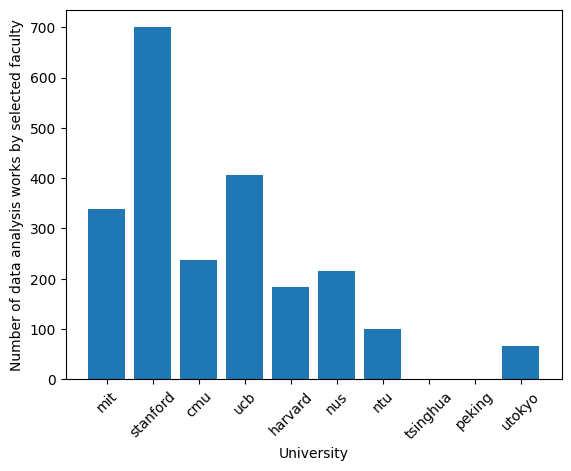

In [108]:
plt.bar(uni_work_counts.keys(), uni_work_counts.values(), color='tab:blue')

plt.ylabel('Number of data analysis works by selected faculty')
plt.xlabel('University')

plt.xticks(rotation=45)
plt.show()

### 6.2 Top 10 Universities by Number of Faculty that Publish in Nature, Science or PNAS (2020-2026)

In [109]:
print("Number of selected faculty per university")
total_faculty = 0

for uni, count in faculty_count.items():
    print(f"{uni}: {count}")

print(f"\nTotal selected faculty: {sum(faculty_count.values())}")

Number of selected faculty per university
mit: 4
stanford: 14
cmu: 7
ucb: 13
harvard: 9
nus: 3
ntu: 1
tsinghua: 0
peking: 0
utokyo: 2

Total selected faculty: 53


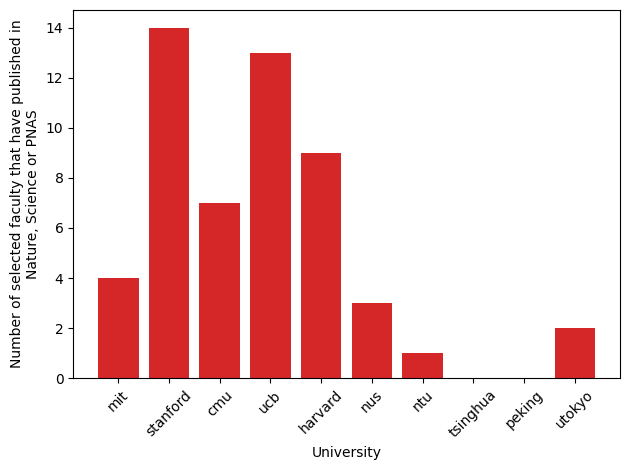

In [110]:
plt.bar(faculty_count.keys(), faculty_count.values(), color='tab:red')

plt.ylabel('Number of selected faculty that have published in Nature, Science or PNAS', wrap=True)
plt.xlabel('University')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 6.3 Top 10 Journals / Conferences Per University by Number of Data Analysis Works (2020-2026)

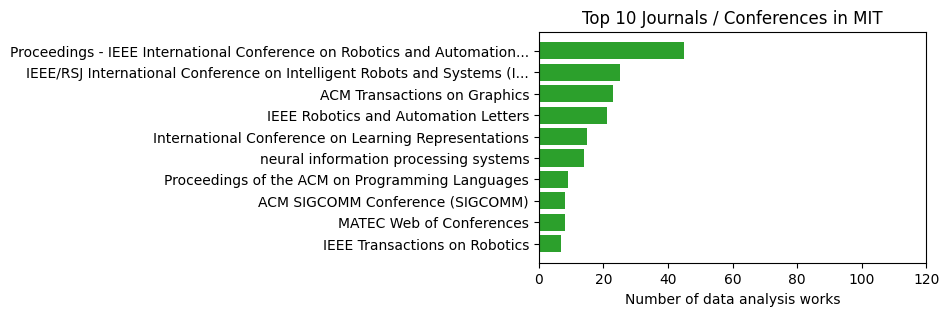

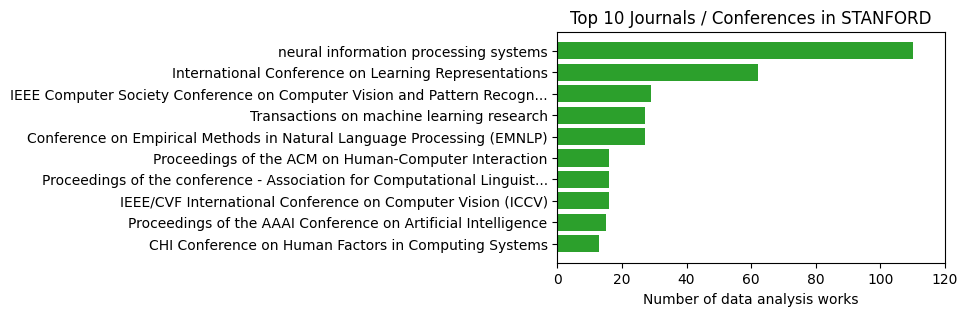

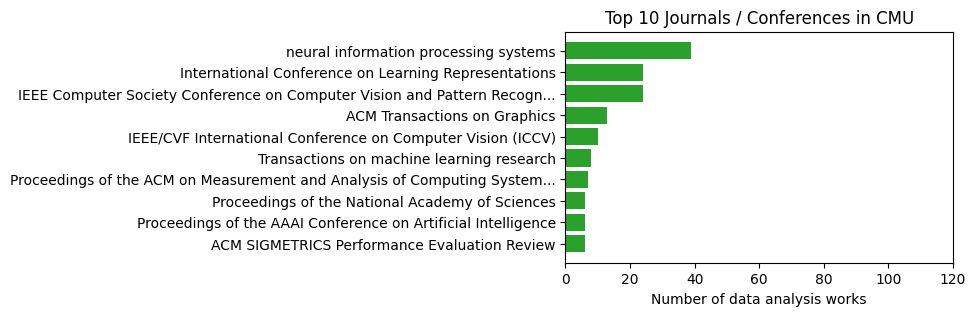

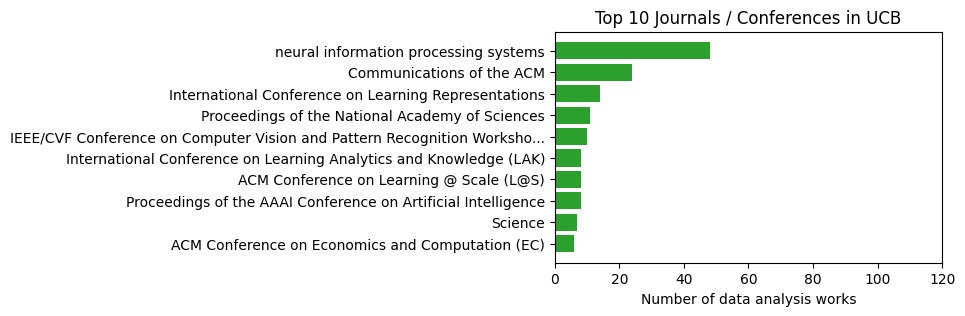

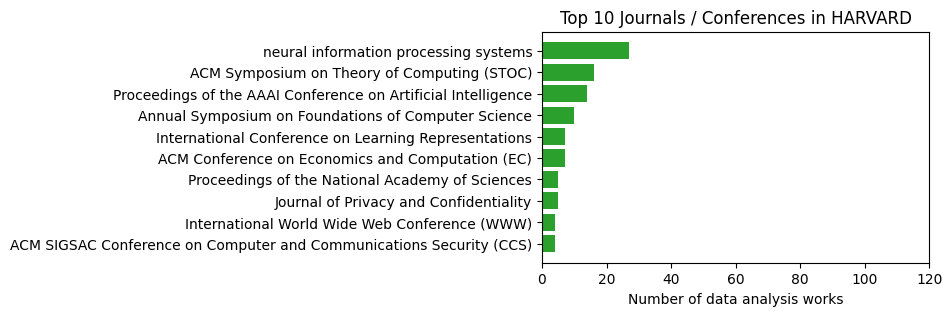

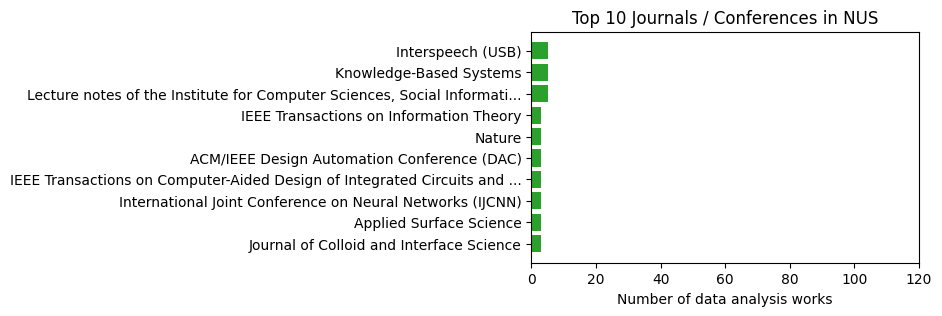

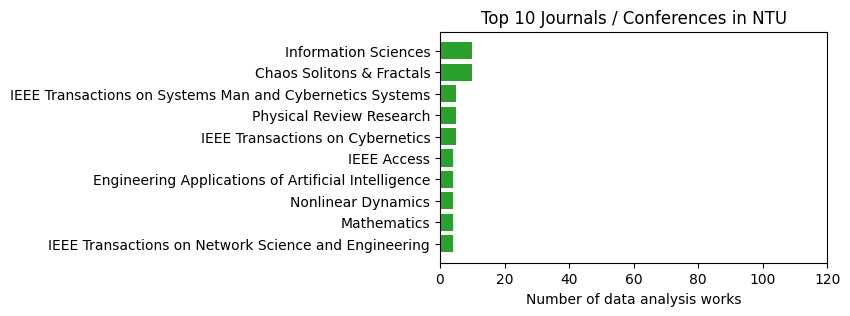

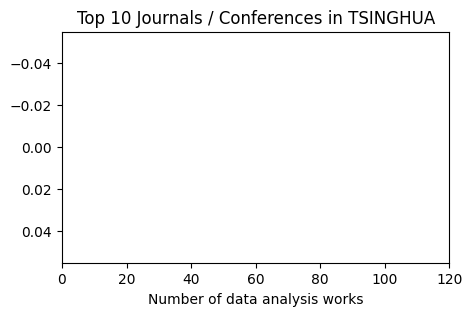

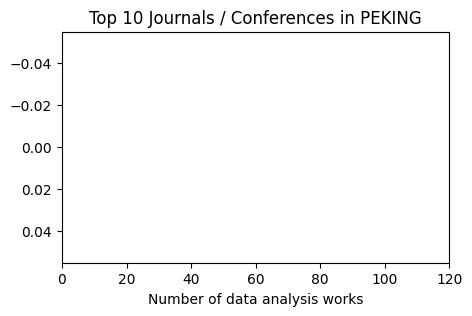

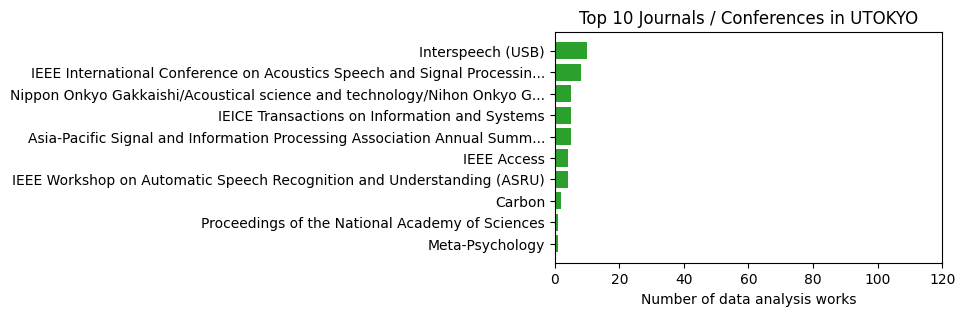

In [138]:
for uni, journals in top_journals_by_uni.items():
    TOP_N = 10  # Get top N journals per university

    top_n = sorted(journals.items(), key=lambda item: len(item[1]["works"]), reverse=True)[:TOP_N]

    journal_names = [truncate_text(journal) for journal, _ in top_n]
    work_counts = [len(issn_works["works"]) for _, issn_works in top_n]

    plt.figure(figsize=(5, 3))
    plt.barh(journal_names, work_counts, color="tab:green")
    plt.gca().invert_yaxis()

    plt.title(f"Top {TOP_N} Journals / Conferences in {uni.upper()}")
    plt.xlabel("Number of data analysis works")
    plt.xlim(0, 120)
    # plt.xticks(range(0, 21, 2))
    plt.show()

### 6.4 Top 3 Journals / Conferences by Number of Data Analysis Works (2020-2026)

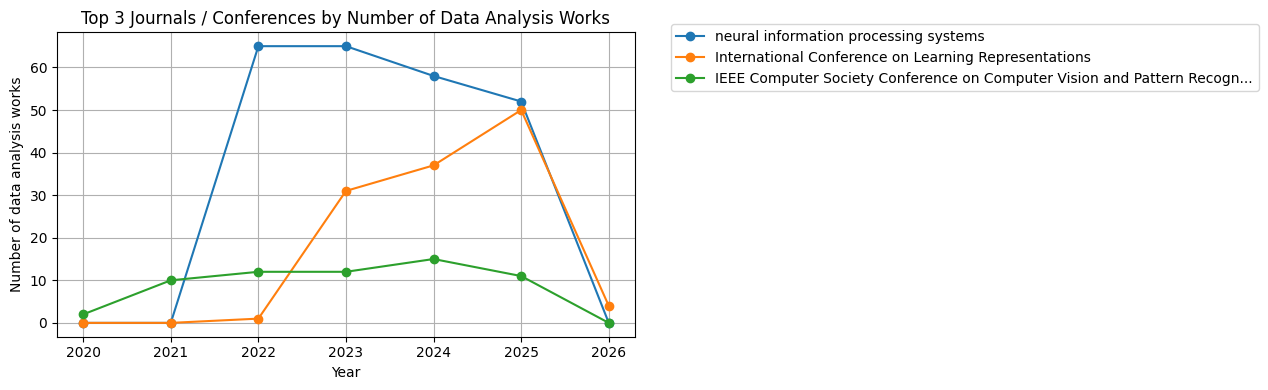

In [139]:
plt.figure(figsize=(13, 4))

years = list(range(2020, 2027))

for journal, issn_works in top_journals[:3]:
    years_list = []
    for work in issn_works["works"]:
        year = datetime.fromisoformat(work["publication_date"]).year
        years_list.append(year)
    
    yearly_counts = Counter(years_list)
    
    counts = []
    for year in years:
        counts.append(yearly_counts[year])

    plt.plot(years, counts, marker="o", label=truncate_text(journal))

plt.xlabel("Year")
plt.ylabel("Number of data analysis works")
plt.title("Top 3 Journals / Conferences by Number of Data Analysis Works")
plt.legend(bbox_to_anchor=(1.05, 1.05), loc="upper left")
plt.grid(True)

plt.tight_layout()
plt.show()

### 6.5 Top Journals / Conferences for each Scholarly Metric

We will evaluate and plot scholarly metrics, each a representation of a journal's research productivity and citation impact. In particular, we look at five metrics:
- 2-Year Mean Citedness
    - The average number of times articles published in a journal are cited over a two-year window.
    - Considerations: A good snapshot of a journal's recent relevance and influence within a short two-year period.

- h-index
    - The maximum value h such that an author has published at least h papers that have each been cited at least h times.
    - Considerations: A good balance between volume and impact. It's unaffected by journals having many unread works or journals with just one very popular work. The h-index also gets exponentially more difficult to increase as it grows.

- i10-index
    - Developed by Google Scholar, it is the number of a journal's published papers that have received at least 10 citations each.
    - Considerations: A good measure of a journal's consistency in publishing quality works. Unlike h-index, the i10-index is more lenient to budding researchers, but it is also affected by self-citations.

- SJR (SCImago Journal Rank)
    - The journal’s total weighted citations over a three-year period divided by its total citable publications in those same years.
    - Considerations: More weight is placed on influential journals, but this means that the score may be influenced by just one very popular work.
    - **Extra:** Q-SJR (SCImago Journal Rank Quartile)
        - Based on the SJR, the journals are grouped into four quartiles (Q1, Q2, Q3, Q4).

- JIF (Journal Impact Factor)
    - The number of citations in the current year to items published in the past two years, divided by the number of citable items in the past two years.
    - Considerations: Similar to 2-Year Mean Citedness, it also uses a two-year window. The score may also be influenced by a single very popular work.
    - **Extra:** JIF (without self-citations)
        - The computation is the same except that we also subtract the following from the numerator: the number of self-citations in the current year to items published in the past two years.
        - Considerations: Useful to grasp the journal's influence on other journals than its own.
        - Both JIF metrics are preserved as self-citations themselves are not inherently detrimental. In fact, according to an [article](https://clarivate.com/academia-government/blog/many-flavors-journal-impact-factor/) by Clarivate (2017), self-citations do not normally play a significant role in JIF scores.


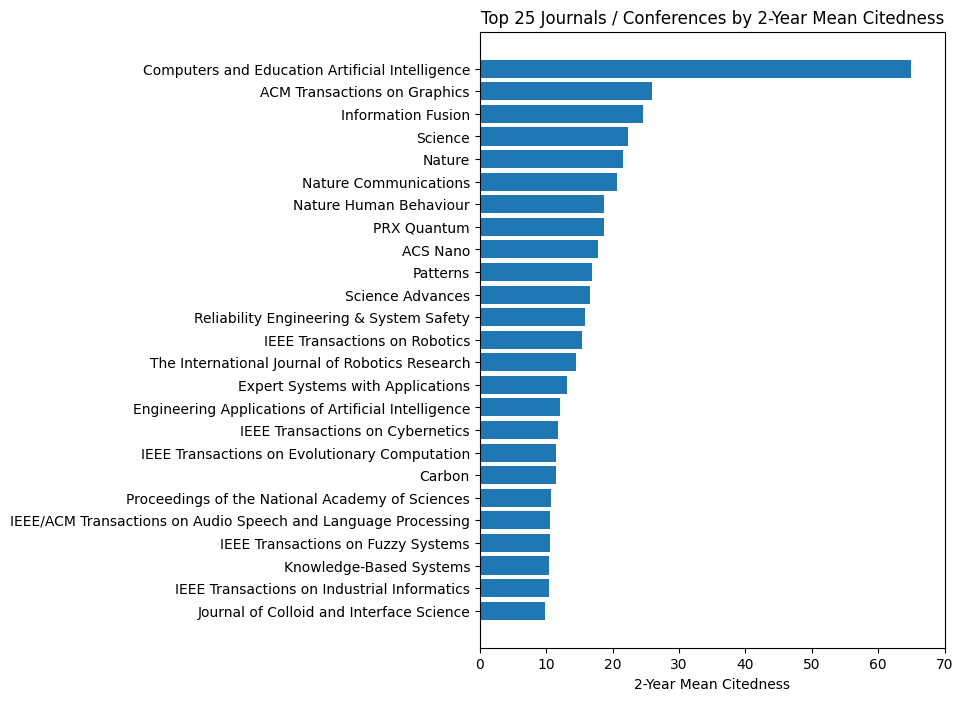

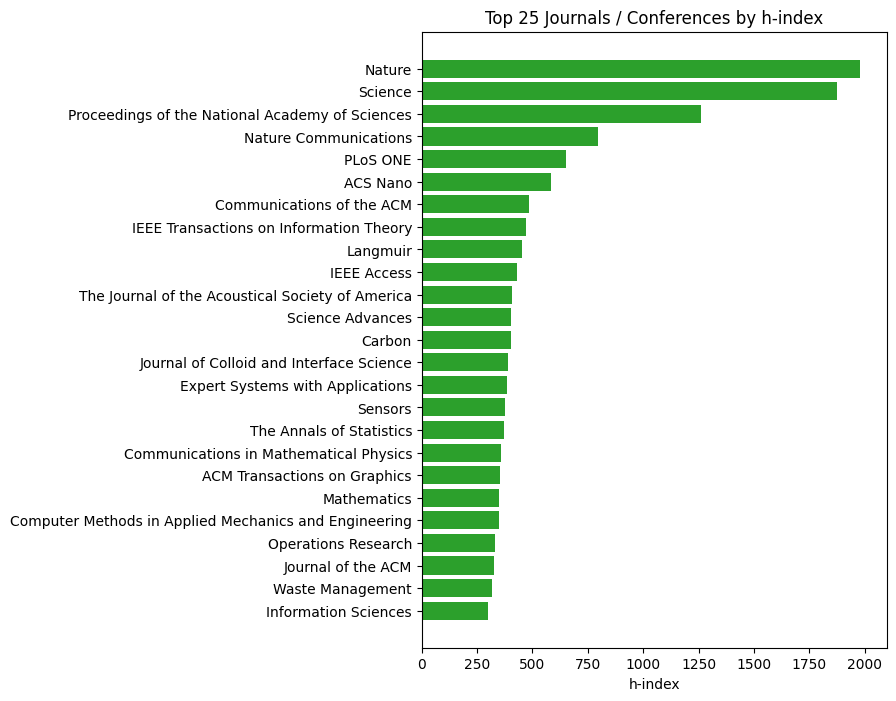

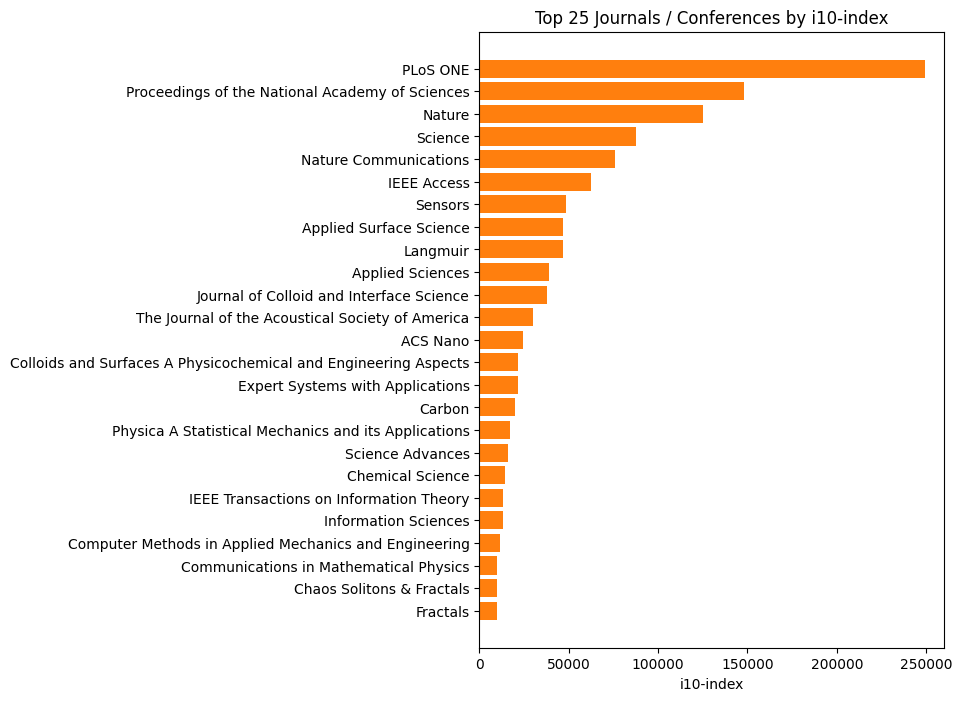

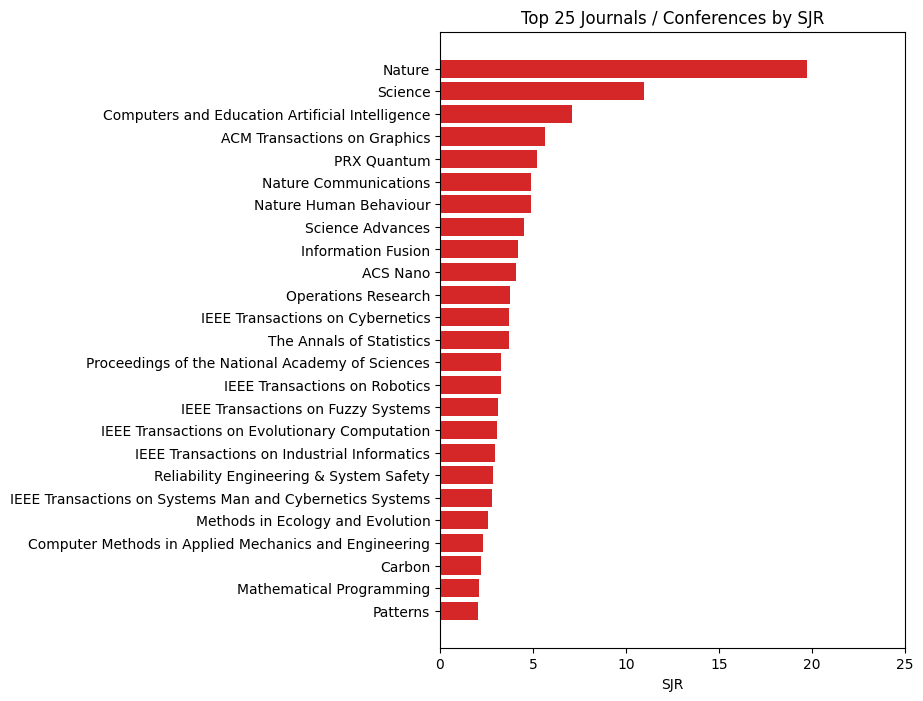

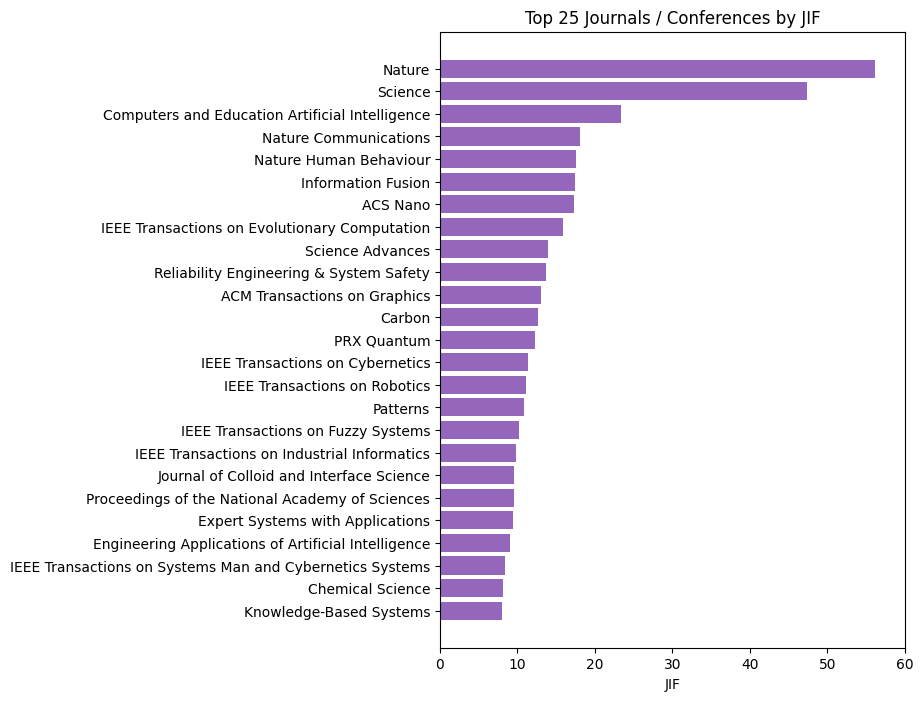

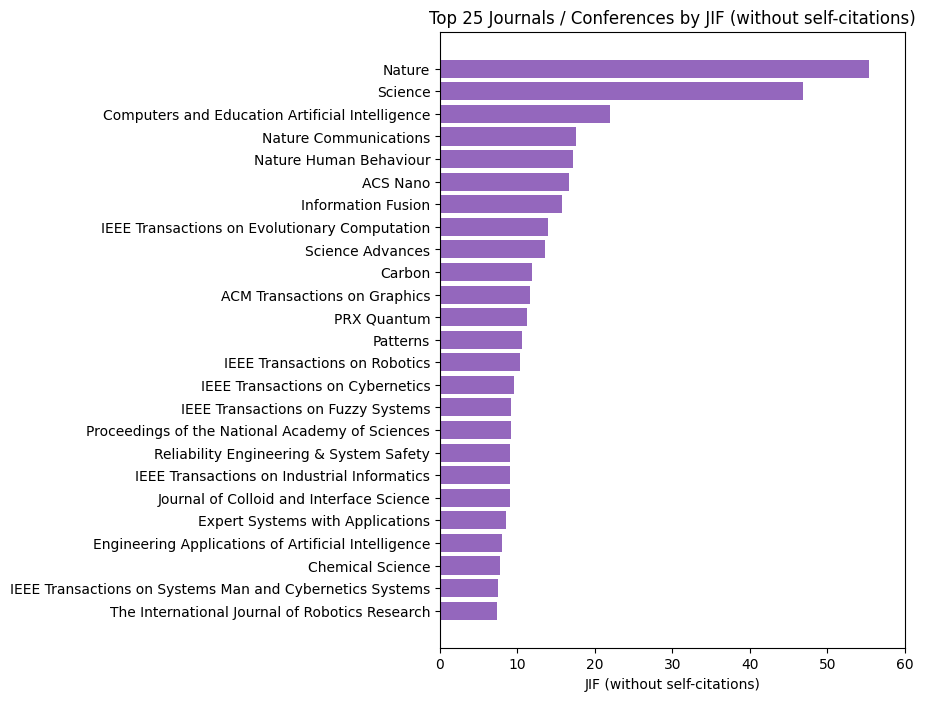

In [146]:
# Top journals by each metric
mean_citedness = (journals_scores_df[["Journal", "2yr_mean_citedness"]].sort_values(by="2yr_mean_citedness", ascending=False).head(TOP_N_JOURNALS))
h_index = (journals_scores_df[["Journal", "h_index"]].sort_values(by="h_index", ascending=False).head(TOP_N_JOURNALS))
i10_index = (journals_scores_df[["Journal", "i10_index"]].sort_values(by="i10_index", ascending=False).head(TOP_N_JOURNALS))
sjr = (journals_scores_df[["Journal", "SJR"]].sort_values(by="SJR", ascending=False).head(TOP_N_JOURNALS))
jif = (journals_scores_df[["Journal", "JIF"]].sort_values(by="JIF", ascending=False).head(TOP_N_JOURNALS))
jif_wo_self_cite = (journals_scores_df[["Journal", "JIF_wo_self_cite"]].sort_values(by="JIF_wo_self_cite", ascending=False).head(TOP_N_JOURNALS))

# 2-Year Mean Citedness
plt.figure(figsize=(6, 8))
plt.barh(mean_citedness["Journal"], mean_citedness["2yr_mean_citedness"], color="tab:blue")
plt.gca().invert_yaxis()
plt.title(f"Top {TOP_N_JOURNALS} Journals / Conferences by 2-Year Mean Citedness")
plt.xlabel("2-Year Mean Citedness")
plt.xlim(0, 70)
plt.subplots_adjust()
plt.show()

# h-index
plt.figure(figsize=(6, 8))
plt.barh(h_index["Journal"], h_index["h_index"], color="tab:green")
plt.gca().invert_yaxis()
plt.title(f"Top {TOP_N_JOURNALS} Journals / Conferences by h-index")
plt.xlabel("h-index")
plt.xlim(0, 2100)
plt.subplots_adjust()
plt.show()

# i10-index
plt.figure(figsize=(6, 8))
plt.barh(i10_index["Journal"], i10_index["i10_index"], color="tab:orange")
plt.gca().invert_yaxis()
plt.title(f"Top {TOP_N_JOURNALS} Journals / Conferences by i10-index")
plt.xlabel("i10-index")
plt.xlim(0, 260000)
plt.subplots_adjust()
plt.show()

# SJR
plt.figure(figsize=(6, 8))
plt.barh(sjr["Journal"], sjr["SJR"], color="tab:red")
plt.gca().invert_yaxis()
plt.title(f"Top {TOP_N_JOURNALS} Journals / Conferences by SJR")
plt.xlabel("SJR")
plt.xlim(0, 25)
plt.subplots_adjust()
plt.show()

# JIF
plt.figure(figsize=(6, 8))
plt.barh(jif["Journal"], jif["JIF"], color="tab:purple")
plt.gca().invert_yaxis()
plt.title(f"Top {TOP_N_JOURNALS} Journals / Conferences by JIF")
plt.xlabel("JIF")
plt.xlim(0, 60)
plt.subplots_adjust()
plt.show()

# JIF without self-citations
plt.figure(figsize=(6, 8))
plt.barh(jif_wo_self_cite["Journal"], jif_wo_self_cite["JIF_wo_self_cite"], color="tab:purple")
plt.gca().invert_yaxis()
plt.title(f"Top {TOP_N_JOURNALS} Journals / Conferences by JIF (without self-citations)")
plt.xlabel("JIF (without self-citations)")
plt.xlim(0, 60)
plt.subplots_adjust()
plt.show()

### 6.6 Top Journal / Conferences Ranking by Clustering

To create the clusters, we will use three metrics: h_index, SJR, and JIF. We exclude the 2-year mean citedness because it is already quite similar to JIF, which makes it redundant. On the other hand, i10-index is very easy to artificially inflate, so we will exclude it. First, let's normalize the metrics.

In [30]:
norm_journals_scores_df = journals_scores_df.copy()

# Normalize scores
scaler = MinMaxScaler()
norm_journals_scores_df[["2yr_mean_citedness", "h_index", "i10_index", "SJR", "JIF", "JIF_wo_self_cite"]] = scaler.fit_transform(
    norm_journals_scores_df[["2yr_mean_citedness", "h_index", "i10_index", "SJR", "JIF", "JIF_wo_self_cite"]]
)

norm_journals_scores_df

,Journal,Issn,2yr_mean_citedness,h_index,i10_index,Q_SJR,SJR,JIF,JIF_wo_self_cite
0,Chaos An Interdisciplinary Journal of Nonlinea...,1054-1500;1089-7682;1527-2443,0.048769,0.078252,0.020500,Q1,0.029949,0.045208,0.036630
1,Fractals,0218-348X;1793-6543,0.085696,0.099593,0.040718,Q1,0.019846,0.037975,0.027473
2,Mathematics,2227-7390,0.000000,0.171748,0.031994,Q2,0.014564,0.027125,0.025641
3,Journal of Statistical Physics,0022-4715;1572-9613,0.014179,0.110264,0.025374,Q2,0.016974,0.005425,0.005495
4,The Journal of the Acoustical Society of America,0001-4966;1520-8524;1520-9024,0.000779,0.201220,0.121412,Q1,0.023436,0.032550,0.023810
...,...,...,...,...,...,...,...,...,...
69,IEEE Transactions on Systems Man and Cyberneti...,2168-2216;2168-2232,0.123403,0.091463,0.017320,Q1,0.132974,0.137432,0.124542
70,Physica A Statistical Mechanics and its Applic...,0378-4371;1873-2119,0.051730,0.121443,0.068886,Q2,0.022256,0.045208,0.038462
71,ACS Nano,1936-0851;1936-086X,0.263945,0.291159,0.098427,Q1,0.199436,0.298373,0.293040
72,Speech Communication,0167-6393;1872-7182,0.054067,0.078252,0.007989,Q1,0.019846,0.037975,0.036630


We'll also create a composite metric which incorporates the aforementioned three metrics so that we could easily compare the journals via a single metric value (as opposed to three). We'll make the range of the composite metric be from 0 to 100; this is purely for ease of interpretation, but we could adjust it however we want. Then, we'll add the composite metric as a new column in the normalized DataFrame. 

In [31]:
# Create the composite score (range of values: 0-100)
composite_scores = (
    norm_journals_scores_df["h_index"] +
    norm_journals_scores_df["SJR"] +
    norm_journals_scores_df["JIF"]
) * (100 / 3)

# Add the score as a new column
norm_journals_scores_df["score"] = composite_scores
norm_journals_scores_df

,Journal,Issn,2yr_mean_citedness,h_index,i10_index,Q_SJR,SJR,JIF,JIF_wo_self_cite,score
0,Chaos An Interdisciplinary Journal of Nonlinea...,1054-1500;1089-7682;1527-2443,0.048769,0.078252,0.020500,Q1,0.029949,0.045208,0.036630,5.113624
1,Fractals,0218-348X;1793-6543,0.085696,0.099593,0.040718,Q1,0.019846,0.037975,0.027473,5.247144
2,Mathematics,2227-7390,0.000000,0.171748,0.031994,Q2,0.014564,0.027125,0.025641,7.114561
3,Journal of Statistical Physics,0022-4715;1572-9613,0.014179,0.110264,0.025374,Q2,0.016974,0.005425,0.005495,4.422118
4,The Journal of the Acoustical Society of America,0001-4966;1520-8524;1520-9024,0.000779,0.201220,0.121412,Q1,0.023436,0.032550,0.023810,8.573505
...,...,...,...,...,...,...,...,...,...,...
69,IEEE Transactions on Systems Man and Cyberneti...,2168-2216;2168-2232,0.123403,0.091463,0.017320,Q1,0.132974,0.137432,0.124542,12.062332
70,Physica A Statistical Mechanics and its Applic...,0378-4371;1873-2119,0.051730,0.121443,0.068886,Q2,0.022256,0.045208,0.038462,6.296915
71,ACS Nano,1936-0851;1936-086X,0.263945,0.291159,0.098427,Q1,0.199436,0.298373,0.293040,26.298898
72,Speech Communication,0167-6393;1872-7182,0.054067,0.078252,0.007989,Q1,0.019846,0.037975,0.036630,4.535762


Let's cluster the journals based on our chosen three metrics. We will use k-means to enforce a fixed number of clusters (namely, three). This way, it is much easier to distinguish the exceptionally prestigious journals from all others.

In [32]:
# Metrics for clustering
features = ["h_index", "SJR", "JIF"]

norm_cluster_df = norm_journals_scores_df.dropna(subset=features).copy()
X = norm_cluster_df[features].to_numpy()

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init="auto"
)

labels = kmeans.fit_predict(X)
norm_cluster_df["cluster"] = labels

Since we are clustering based on three metrics, we will use a 3D plot, where each metric represents an axis.

In [33]:
clusters = sorted(norm_cluster_df["cluster"].unique())

cmap = plt.cm.tab10
norm = mcolors.Normalize(
    vmin=norm_cluster_df["cluster"].min(),
    vmax=norm_cluster_df["cluster"].max()
)

cluster_colors = {
    cluster: cmap(norm(cluster))
    for cluster in clusters
}

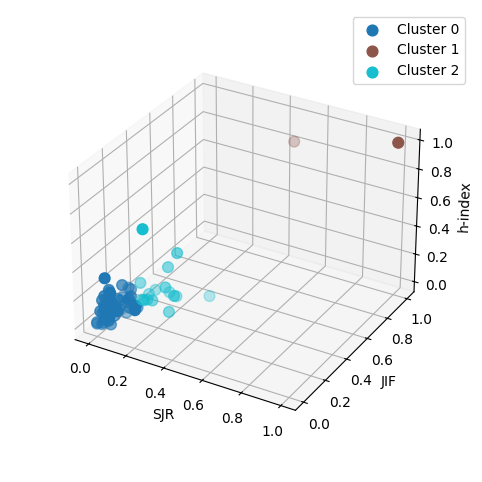

In [34]:
# 3D plot
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")

for cluster in clusters:
    subset = norm_cluster_df[norm_cluster_df["cluster"] == cluster]

    ax.scatter(
        subset["SJR"],
        subset["JIF"],
        subset["h_index"],
        color=cluster_colors[cluster],
        label=f"Cluster {cluster}",
        s=60,
    )

ax.set_xlabel("SJR")
ax.set_ylabel("JIF")
ax.set_zlabel("h-index")
ax.set_box_aspect(None, zoom=0.85)
ax.legend()

plt.show()

Based on our plot, Cluster 1 (brown) appears to contain two outstanding journals — we'll call this exclusive cluster the **Premium** tier.

Cluster 2 (cyan) contains a good number of noteworthy journals above the majority, though far behind the Premium tier — we'll call this the **Leading** tier.

Finally, the majority of journals in this list belong to Cluster 0 (blue), which we'll call the **Reputable** tier. Despite making up the majority of journals, do note that this is not to say that the journals in this cluster are insignificant or unreputable. Recall that we had initially narrowed our selection to the top ~100 journals from prestigious universities, so all the journals in this list are already a cut above the wider demographic of journals. Don't be fooled by the seemingly low numbers — recall that the values are normalized.

Let's inspect the journals again in a 2D plot, where we simply use the composite score on both axes.

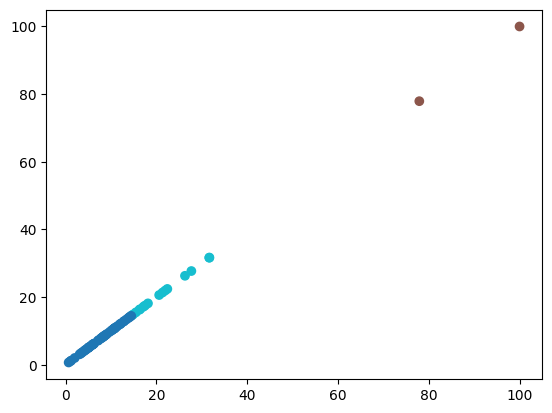

In [35]:
plt.scatter(
    norm_cluster_df["score"],
    norm_cluster_df["score"],
    color=norm_cluster_df["cluster"].map(cluster_colors),
)

Based on the 2D plot, the Premium tier represents journals with a composite score of roughly `>= 75`. All other tiers have a composite score of roughly `< 75`.

To help with interpretability, let's un-normalize the metrics.

In [36]:
cluster_df = journals_scores_df.dropna(subset=features).copy()

cluster_df["score"] = composite_scores
cluster_df["cluster"] = labels

In [37]:
summary = (
    cluster_df
    .groupby("cluster")
    .agg(
        count=("cluster", "size"),
        h_index=("h_index", "mean"),
        SJR=("SJR", "mean"),
        JIF=("JIF", "mean"),
        score=("score", "mean"),
    )
)

print(summary)

         count      h_index        SJR        JIF      score
cluster                                                     
0           56   236.928571   1.267393   4.510714   7.831927
1            2  1928.000000  15.330500  51.700000  88.958650
2           16   380.250000   4.062938  14.193750  20.874836


One may note the metric averages of each tier which is displayed above. The Premium tier (Cluster 1) consists of only 2 journals. The Leading tier (Cluster 2) consists of 16, and the Reputable tier (Cluster 0) consists of 56 journals.

Let's inspect what these two Premium journals are.

In [38]:
# Premium tier (Cluster 1) ranked by composite metric
cluster_df[cluster_df["cluster"] == 1].sort_values(
    by="score",
    ascending=False
)[["Journal", "2yr_mean_citedness", "h_index", "i10_index", "Q_SJR", "SJR", "JIF", "JIF_wo_self_cite", "score"]]

,Journal,2yr_mean_citedness,h_index,i10_index,Q_SJR,SJR,JIF,JIF_wo_self_cite,score
13,Nature,21.53,1981,125316,Q1,19.713,56.1,55.3,100.000000
33,Science,22.27,1875,87877,Q1,10.948,47.3,46.9,77.917301


Based on the composite metric, it would be logical to rank the top 2 journals in data analysis as follows:
1. Nature
2. Science

Impressively, **Nature** boasts the highest h-index, SJR, and JIF scores — achieving a perfect composite score of 100!

Finally, let's also inspect the remaining journals in the lower tiers.

In [39]:
# Leading tier (Cluster 2) ranked by composite metric
cluster_df[cluster_df["cluster"] == 2].sort_values(
    by="score",
    ascending=False
)[["Journal", "2yr_mean_citedness", "h_index", "i10_index", "Q_SJR", "SJR", "JIF", "JIF_wo_self_cite", "score"]]

,Journal,2yr_mean_citedness,h_index,i10_index,Q_SJR,SJR,JIF,JIF_wo_self_cite,score
6,Nature Communications,20.74,794,75696,Q1,4.904,18.1,17.5,31.675092
68,Proceedings of the National Academy of Sciences,10.67,1262,147817,Q1,3.283,9.5,9.2,31.647135
21,Computers and Education Artificial Intelligence,64.97,151,518,Q1,7.083,23.4,21.9,27.703652
71,ACS Nano,17.73,586,24532,Q1,4.102,17.3,16.7,26.298898
36,ACM Transactions on Graphics,25.92,355,5031,Q1,5.633,13.0,11.6,22.411468
73,Science Advances,16.61,405,15955,Q1,4.534,13.9,13.6,21.922214
11,Nature Human Behaviour,18.75,206,1501,Q1,4.896,17.5,17.2,21.340403
67,Information Fusion,24.53,237,2877,Q1,4.197,17.4,15.7,20.610322
38,IEEE Transactions on Evolutionary Computation,11.54,261,1842,Q1,3.045,15.9,14.0,18.143436
7,PRX Quantum,18.71,131,1232,Q1,5.222,12.3,11.2,17.492925


In [40]:
# Reputable tier (Cluster 0) ranked by composite metric
cluster_df[cluster_df["cluster"] == 0].sort_values(
    by="score",
    ascending=False
)[["Journal", "2yr_mean_citedness", "h_index", "i10_index", "Q_SJR", "SJR", "JIF", "JIF_wo_self_cite", "score"]]

,Journal,2yr_mean_citedness,h_index,i10_index,Q_SJR,SJR,JIF,JIF_wo_self_cite,score
63,Expert Systems with Applications,13.16,386,21470,Q1,1.939,9.4,8.5,14.452024
16,Journal of Colloid and Interface Science,9.90,391,37876,Q1,1.642,9.6,9.0,14.149574
54,Communications of the ACM,5.28,485,7652,Q1,1.540,7.1,6.9,14.060424
9,The Annals of Statistics,9.74,373,5316,Q1,3.697,3.7,3.3,13.801158
62,Computer Methods in Applied Mechanics and Engi...,9.40,348,11870,Q1,2.323,7.6,6.5,13.379812
5,PLoS ONE,4.32,653,249093,Q1,0.726,2.8,2.7,12.922577
42,Operations Research,5.85,331,5574,Q1,3.759,3.0,2.8,12.773817
32,Chemical Science,8.14,293,14597,Q1,2.011,8.1,7.7,12.216293
69,IEEE Transactions on Systems Man and Cyberneti...,8.71,193,4330,Q1,2.806,8.4,7.5,12.062332
39,The International Journal of Robotics Research,14.51,286,2588,Q1,2.022,7.7,7.3,11.875423


### 6.7 Top Keywords / Keyphrases per Journal / Conference

This section identifies common keywords/keyphrases that are present in accepted works. This could give us a broad idea of the topics that each top journal publishes (outside of what the journal iteslf declares). For this, we will use the abstracts of works to infer the common keywords/keyphrases of each journal. Note that while most works have their abstracts available on OpenAlex, a very small fraction of works don't — this is a limitation of OpenAlex.

We will try three different approaches:
1. Naive top k words
2. KeyBERT
3. BERTopic

As an example, we'll get the top keywords of the journals in the **Premium** and **Leading** tiers.

In [41]:
# Tiers: Premium (Cluster 1) and Leading (Cluster 2) 
premium_leading = (
    cluster_df[cluster_df["cluster"].isin([1, 2])]
    .sort_values(by="score", ascending=False)["Journal"]
    .tolist()
)

print(premium_leading)

['Nature', 'Science', 'Nature Communications', 'Proceedings of the National Academy of Sciences', 'Computers and Education Artificial Intelligence', 'ACS Nano', 'ACM Transactions on Graphics', 'Science Advances', 'Nature Human Behaviour', 'Information Fusion', 'IEEE Transactions on Evolutionary Computation', 'PRX Quantum', 'Carbon', 'IEEE Transactions on Cybernetics', 'Reliability Engineering & System Safety', 'IEEE Transactions on Robotics', 'IEEE Transactions on Fuzzy Systems', 'IEEE Transactions on Industrial Informatics']


We'll also create a custom list of words and symbols to exclude from analysis since these are artifacts of the way OpenAlex stores the abstracts.

In [42]:
# List of words to exclude
EXCLUDED_WORDS = {
    "<", ">",
    "/", "=", ".",
    "abstract",
    "al.",
    "http",
    "www",
    "doi",
    "org",
    "com",
    "edu",
    "xmlns",
    "xlink",
    "href",
    "xml",
    "html",
    "copyright",
}

#### Naive top k words

In this approach, we simply count the number of occurrences of each word (excluding stop words) for each journal and present the top k words. We also exclude common stopwords as they are not very insightful.

In [43]:
stop_words = get_stop_words('en')

for journal in premium_leading:
    word_counts = Counter()
    works = journals_combined[journal]["works"]

    print(f"{journal}: {len(works)}")

    for work in works:
        abstract_index = work["abstract_inverted_index"]

        if not abstract_index:
            continue

        for word, positions in abstract_index.items():
            if word.lower() in stop_words or word_contains_any_listwords(word, EXCLUDED_WORDS):
                continue

            word_counts[word.lower()] += len(positions)

    print(word_counts.most_common(20))
    print()

Nature: 24
[('quantum', 9), ('3d', 7), ('model', 7), ('demonstrate', 6), ('methods', 5), ('approach', 5), ('systems', 5), ('benchmark', 5), ('optimization', 5), ('decoding', 5), ('hidden', 5), ('interaction', 5), ('three-dimensional', 4), ('holography', 4), ('physically', 4), ('image', 4), ('range', 4), ('process', 4), ('introduce', 4), ('human', 4)]

Science: 20
[('quantum', 15), ('policy', 7), ('liquid', 7), ('plastic', 6), ('informed', 4), ('by,', 4), ('facilitate', 4), ('generation', 4), ('of,', 4), ('scientific', 4), ('birth', 3), ('method', 3), ('experiment', 3), ('model', 3), ('machine', 3), ('data', 3), ('learning', 3), ('affect', 3), ('physical', 3), ('experiments', 3)]

Nature Communications: 13
[('droplet', 12), ('demonstrate', 10), ('models', 9), ('rebound', 7), ('motion', 6), ('droplets', 6), ('danger', 5), ('here,', 5), ('autonomous', 5), ('method', 5), ('internal', 5), ('behaviors', 5), ('wealth', 5), ('angle', 5), ('codas', 4), ('remains', 4), ('exhibit', 4), ('however,

Evidently, this approach is not very clever. It's worth noting that the most common word by far is the word "data". This makes sense given that we initially filtered the works by data analysis topics only.

#### KeyBERT

Here's a more clever approach: we display the top keywords/keyphrases and their corresponding cosine similarity scores to measure how representative each keyword is to all the works in the journal. These scores typically range from 0.0 to 1.0, with scores that are 0.4 and above indicating good relevance to the works of the journal.

In [44]:
kw_model = KeyBERT()

for journal in premium_leading:
    works = journals_combined[journal]["works"]
    abstracts = []

    for work in works:
        abstract = reconstruct_abstract(work["abstract_inverted_index"], EXCLUDED_WORDS)

        if abstract:
            abstracts.append(abstract)

    combined_abstracts = " ".join(abstracts)
    
    vectorizer = CountVectorizer(stop_words="english", ngram_range=(1,2), max_features=3000)
    keybert_keywords = kw_model.extract_keywords(combined_abstracts, vectorizer=vectorizer, top_n=5, use_mmr=True)

    print(f"{journal}: {len(works)}")
    print(keybert_keywords)
    print()

Nature: 24
[('3d hologram', 0.6474), ('cnn trained', 0.3423), ('blur dissipation', 0.2768), ('scale cgh', 0.2529), ('runtime making', 0.1708)]

Science: 20
[('participants feeds', 0.4725), ('whale birth', 0.3969), ('attitudes partisan', 0.39), ('species behavior', 0.3561), ('kinship barriers', 0.3287)]

Nature Communications: 13
[('warming trends', 0.4794), ('fires', 0.4678), ('danger mountainous', 0.4452), ('sperm whale', 0.3794), ('including elevationally', 0.2532)]

Proceedings of the National Academy of Sciences: 39
[('elevation fires', 0.6524), ('climate trends', 0.4605), ('montane mesic', 0.2768), ('vapor pressure', 0.2484), ('prioritizing reconstructed', 0.1449)]

Computers and Education Artificial Intelligence: 2
[('psychometric measurement', 0.4953), ('questions gold', 0.3591), ('difficulty discrimination', 0.3528), ('generated items', 0.2705), ('openstax lessons', 0.2313)]

ACS Nano: 2
[('laser sintering', 0.5096), ('refractory metals', 0.4618), ('soot nanoparticles', 0.4432)

#### BERTopic

Another approach is to cluster topics using BERTopic. It uses TF-IDF (Term Frequency-Inverse Document Frequency) to evaluate the importance of each word to a corpus. In this implementation, we use AllenAI SPECTER which is a pretrained language model on scientific documents to generate embeddings and identify groups of semantically related works.

In [45]:
embedding_model = SentenceTransformer("allenai-specter")

vectorizer_model = CountVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=1
)

abstracts = []
journal_names = []

for journal, issn_works in journals_combined.items():
    works = issn_works["works"]

    for work in works:
        abstract = reconstruct_abstract(work["abstract_inverted_index"], EXCLUDED_WORDS)

        if abstract:
            abstracts.append(abstract)
            journal_names.append(journal)

representation_model = KeyBERTInspired()
topic_model = BERTopic(embedding_model=embedding_model, vectorizer_model=vectorizer_model, representation_model=representation_model)

topics, probs = topic_model.fit_transform(abstracts)

In [46]:
topic_info_df = topic_model.get_topic_info()
topic_info_df

,Topic,Count,Name,Representation,Representative_Docs
0,-1,481,-1_datasets_data_search_existing,"[datasets, data, search, existing, proposed, e...",[This paper explores the use of synthetic data...
1,0,252,0_generate_existing_performance_finetuning,"[generate, existing, performance, finetuning, ...",[Widely used language models (LMs) are typical...
2,1,66,1_generated_existing_content_design,"[generated, existing, content, design, results...",[Millions of learners worldwide are now using ...
3,2,61,2_existing_techniques_demonstrate_performance,"[existing, techniques, demonstrate, performanc...",[As the scale of machine learning models incre...
4,3,60,3_image generation_image_generative_generated ...,"[image generation, image, generative, generate...",[The stunning qualitative improvement of recen...
5,4,55,4_generated_proposed_synthesized_converted,"[generated, proposed, synthesized, converted, ...",[We propose novel deep speaker representation ...
6,5,51,5_photo realistic_camera_reconstruction_multi ...,"[photo realistic, camera, reconstruction, mult...",[ Synthesizing photo‐realistic images and vide...
7,6,46,6_high resolution_recent_increased_dry,"[high resolution, recent, increased, dry, dry ...",[Can mobile phone data improve program targeti...
8,7,44,7_image_images_image quality_rendering,"[image, images, image quality, rendering, dire...",[Holographic near-eye displays offer unprecede...
9,8,44,8_generate_scene_machines_recent,"[generate, scene, machines, recent, demonstrat...",[Robots are often built from standardized asse...


In [47]:
# Track number of works for each topic under a journal
journal_topics = defaultdict(Counter)
for journal, topic in zip(journal_names, topics):
    if journal in premium_leading:
        if topic != -1:
            journal_topics[journal][topic] += 1

# Track percentage of works too
journal_topics_percent = copy.deepcopy(journal_topics)
for journal in journal_topics_percent:
    total = sum(journal_topics_percent[journal].values())

    for topic in journal_topics_percent[journal]:
        journal_topics_percent[journal][topic] /= total

# Display the 5 most representative topics per journal (via keywords)
for journal, journal_topic_counts in journal_topics.items():
    print(journal)
    temp_ctr = 0

    # Top 5 topics only
    for topic_id, count in journal_topic_counts.most_common(6):
        representation = topic_info_df['Representation'][topic_id + 1]
        if any(word.strip() for word in representation):
            print(f"{journal_topics_percent[journal][topic_id]:.0%} ({count}): \t{topic_info_df['Representation'][topic_id + 1]}")
            temp_ctr += 1

            if temp_ctr == 5:
                break

    print()

Science Advances
50% (2): 	['multi objective', 'offline multi', 'pareto optimal', 'improvement', 'objective', 'optimization', 'objective optimization', 'gamut', 'demonstrate', 'acquisition']
25% (1): 	['high resolution', 'recent', 'increased', 'dry', 'dry hot', 'imagery', 'resolution', 'machine', 'crop', 'model']
25% (1): 	['image', 'images', 'image quality', 'rendering', 'direct view', 'color', 'demonstrate', 'content', 'augmented', 'camera']

Proceedings of the National Academy of Sciences
14% (4): 	['gasser', 'joseph gasser', 'ness', 'jeannette witherell', 'author blau', 'witherell', 'gerald', 'gasser urs', 'robin', 'haug gerald']
10% (3): 	['high resolution', 'recent', 'increased', 'dry', 'dry hot', 'imagery', 'resolution', 'machine', 'crop', 'model']
7% (2): 	['generative', 'generative agents', 'generative agent', 'large language', 'generative ai', 'practitioners', 'populated', 'agents', 'generic', 'natural']
7% (2): 	['share', 'demonstrate', 'far right', 'model', 'set', 'results'

Here, we can see the percentage and number of works of each journal that satisfy certain topics and their respective keywords/keyphrases.